# Домашнее задание №1. Классификация категории товара по названию

Цель проекта — предсказать единую категорию 'subject' по русскому названию товара. В ноутбуке выполняются аудит данных, EDA, TF-IDF baseline, улучшенная модель на символьных и словарных n-граммах, а также формирование submission для Kaggle.

Основная метрика соревнования — 'F1-macro', поэтому при проверке учитываются все классы, включая редкие.

## 1. Импорты и настройки

Все параметры эксперимента собраны в одном месте. Фиксируем random seed для воспроизводимости разбиения и обучения моделей.

In [1]:
from pathlib import Path
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import SGDClassifier

SEED = 42
VALID_SIZE = 0.2
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)

## 2. Загрузка данных

Ноутбук рассчитан на Kaggle. Путь к данным определяется автоматически, поэтому код можно запускать как в Kaggle Notebook, так и локально, если рядом доступны 'train.csv', 'test.csv' и 'sample_submission.csv'.

In [2]:
data_dir = Path('data')

train = pd.read_csv(data_dir / 'train.csv')
test = pd.read_csv(data_dir / 'test.csv')
sample_path = data_dir / 'sample_submission.csv'
sample_submission = pd.read_csv(sample_path) if sample_path.exists() else None

required_train_columns = {'id', 'text', 'subject'}
required_test_columns = {'id', 'text'}
assert required_train_columns.issubset(train.columns)
assert required_test_columns.issubset(test.columns)

print(f'Папка с данными: {data_dir.resolve()}')
print(f'train: {train.shape}')
print(f'test: {test.shape}')
print(f'Количество классов: {train["subject"].nunique()}')
display(train.head())
display(test.head())

Папка с данными: /home/froschin/work/masters_degree_Roshchin_M25-555/модели_на_базе_архитектуры_трансформер/data
train: (31670, 3)
test: (2046, 2)
Количество классов: 341


,id,text,subject
0,34b735ace73a4812,Брюки с заниженной посадкой в молочном цвете,брюки
1,216dddb6b09b5864,Туфли,туфли
2,29bf639b34ef56dd,Винное плиссированное платье Винное плиссированное платье,платья
3,b96d8cf3fd42b62f,Футболка из дышащего хлопка,футболки
4,aa85d9fde0e28e82,Кроссовки и кеды J.j.delacroix,кроссовки


,id,text
0,a83e837ab5fb2f99,Брюки из воздушной крапивы с полупрозрачным эффектом
1,5d6af21d7c229ad6,Короткий стеганый пуховик
2,d7ee0506ccd4b1bc,"Классическая водолазка с полупрозрачными вставками (Черный, XS)"
3,1bf5b0ed69dc6cbd,black_sensitive dress 2
4,27cb9547fd44b966,Тапули SQ beige замшевые


## 3. EDA и контроль качества данных

Проверяем пропуски, дубликаты, длину названий и распределение классов. Дубликаты названий оставляем: по условию соревнования они могут соответствовать разным карточкам и являются частью обучающей выборки.

In [3]:
def normalize_text(text):
    text = str(text).lower()
    text = text.replace('ё', 'е')
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

train['text_clean'] = train['text'].map(normalize_text)
test['text_clean'] = test['text'].map(normalize_text)
train['text_length'] = train['text_clean'].str.len()
train['word_count'] = train['text_clean'].str.split().str.len()
test['text_length'] = test['text_clean'].str.len()
test['word_count'] = test['text_clean'].str.split().str.len()

audit = pd.DataFrame({
    'Проверка': [
        'Пропуски в train',
        'Пропуски в test',
        'Пустые названия в train',
        'Дубликаты id в train',
        'Дубликаты id в test',
        'Дубликаты названий в train',
        'Пересечения названий train/test'
    ],
    'Значение': [
        int(train[['text', 'subject']].isna().sum().sum()),
        int(test['text'].isna().sum()),
        int((train['text_clean'] == '').sum()),
        int(train['id'].duplicated().sum()),
        int(test['id'].duplicated().sum()),
        int(train['text_clean'].duplicated().sum()),
        int(train['text_clean'].isin(set(test['text_clean'])).sum())
    ]
})
display(audit)

print('Статистика длины названий:')
display(train[['text_length', 'word_count']].describe().round(2))

class_distribution = train['subject'].value_counts()
print(f'Минимальный размер класса: {class_distribution.min()}')
print(f'Максимальный размер класса: {class_distribution.max()}')
display(class_distribution.head(20).rename('count').to_frame())

,Проверка,Значение
0,Пропуски в train,0
1,Пропуски в test,0
2,Пустые названия в train,0
3,Дубликаты id в train,0
4,Дубликаты id в test,0
5,Дубликаты названий в train,23575
6,Пересечения названий train/test,9


Статистика длины названий:


,text_length,word_count
count,31670.00,31670.00
mean,18.92,2.83
std,12.97,1.99
min,1.00,1.00
25%,8.00,1.00
50%,16.00,2.00
75%,25.00,4.00
max,106.00,17.00


Минимальный размер класса: 1
Максимальный размер класса: 2764


,count
subject,
кроссовки,2764
туфли,2364
ботинки,2153
платья,1526
кольца,1454
лоферы,1433
серьги,1298
брюки,1062
ботильоны,1021


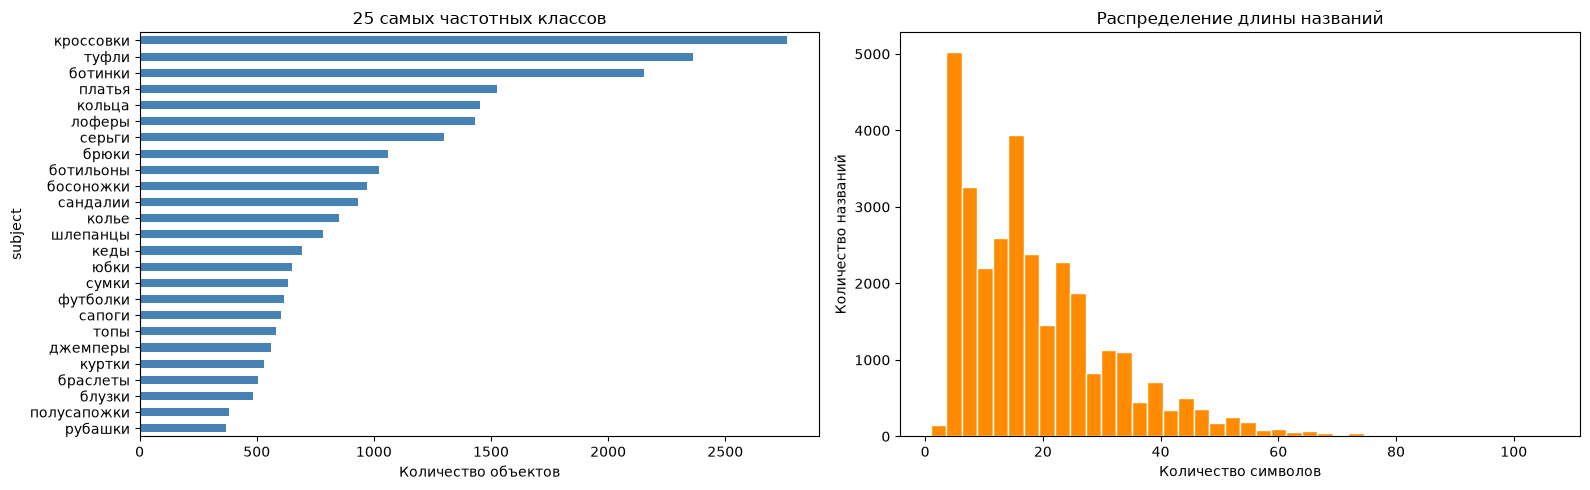

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
class_distribution.head(25).sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('25 самых частотных классов')
axes[0].set_xlabel('Количество объектов')
axes[1].hist(train['text_length'], bins=40, color='darkorange', edgecolor='white')
axes[1].set_title('Распределение длины названий')
axes[1].set_xlabel('Количество символов')
axes[1].set_ylabel('Количество названий')
plt.tight_layout()
plt.show()

### Вывод по EDA

В задаче много классов и заметный дисбаланс: редкие категории будут особенно важны для 'F1-macro'. Поэтому в качестве основной модели используется 'class_weight=balanced', а при валидации macro-F1 считается по полному списку классов. Названия короткие и содержат полезные маркеры категории — слова о типе товара, материале, цвете и характеристиках.

Дубликаты названий внутри train не удаляются, поскольку они разрешены условием соревнования. Разбиение для локальной проверки выполняется по группам одинаковых нормализованных названий, чтобы одинаковая строка не попадала одновременно в train и validation.

## 4. Локальная валидация

Используем 'GroupShuffleSplit': группой является нормализованное название товара. Это уменьшает риск завышенной оценки из-за повторяющихся названий. Для редких классов часть классов может не попасть в validation, поэтому macro-F1 вычисляется с 'zero_division=0'.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=VALID_SIZE, random_state=SEED)
train_indices, valid_indices = next(
    splitter.split(train['text_clean'], train['subject'], groups=train['text_clean'])
)

train_part = train.iloc[train_indices].copy()
valid_part = train.iloc[valid_indices].copy()
all_classes = np.sort(train['subject'].unique())

print(f'Обучающая часть: {train_part.shape[0]} объектов')
print(f'Валидационная часть: {valid_part.shape[0]} объектов')
print(f'Пересечения групп: {set(train_part["text_clean"]) & set(valid_part["text_clean"])}')
print(f'Классов в train_part: {train_part["subject"].nunique()} из {len(all_classes)}')
print(f'Классов в valid_part: {valid_part["subject"].nunique()} из {len(all_classes)}')

Обучающая часть: 25429 объектов
Валидационная часть: 6241 объектов
Пересечения групп: set()
Классов в train_part: 310 из 341
Классов в valid_part: 164 из 341


## 5. Baseline: словарный TF-IDF и SGDClassifier

Baseline использует word n-граммы размера 1–2. 'SGDClassifier' обучает линейный SVM на разреженной матрице значительно быстрее, чем полный перебор итераций у 'LinearSVC'.

In [6]:
baseline_vectorizer = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    max_features=80000
)

In [7]:
X_train_baseline = baseline_vectorizer.fit_transform(train_part['text_clean'])
X_valid_baseline = baseline_vectorizer.transform(valid_part['text_clean'])

In [8]:
baseline_model = SGDClassifier(
    loss='hinge',
    alpha=1e-5,
    max_iter=30,
    tol=1e-3,
    class_weight='balanced',
    average=True,
    n_jobs=-1,
    random_state=SEED
)
baseline_model.fit(X_train_baseline, train_part['subject'])

,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",1e-05
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",30
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"class_weight class_weight: dict, {class_label: weight} or ""balanced"", default=NonePreset for the class_weight fit parameter.Weights associated with classes. If not given, all classesare supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"average average: bool or int, default=FalseWhen set to `True`, computes the averaged SGD weights across allupdates and stores the result in the ``coef_`` attribute. If set toan int greater than 1, averaging will begin once the total number ofsamples seen reaches `average`. So ``average=10`` will beginaveraging after seeing 10 samples.Integer values must be in the range `[1, n_samples]`.",True
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ra

In [9]:
baseline_predictions = baseline_model.predict(X_valid_baseline)
baseline_f1 = f1_score(
    valid_part['subject'],
    baseline_predictions,
    labels=all_classes,
    average='macro',
    zero_division=0
)
print(f'Размер baseline-матрицы: {X_train_baseline.shape}')
print(f'Baseline validation F1-macro: {baseline_f1:.5f}')

Размер baseline-матрицы: (25429, 14775)
Baseline validation F1-macro: 0.27538


## 6. Улучшенная модель: word + character TF-IDF

К словарным n-граммам добавляем символьные n-граммы. Они устойчивее к опечаткам, словоформам, артикулам, смешению кириллицы и латиницы, а также хорошо выделяют окончания и устойчивые части названий.

In [10]:
def make_feature_union():
    return FeatureUnion([
        ('word', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True,
            max_features=100000
        )),
        ('char', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=100000
        ))
    ])

feature_union = make_feature_union()
X_train_final = feature_union.fit_transform(train_part['text_clean'])
X_valid_final = feature_union.transform(valid_part['text_clean'])

final_model = SGDClassifier(
    loss='hinge',
    alpha=1e-5,
    max_iter=40,
    tol=1e-3,
    class_weight='balanced',
    average=True,
    n_jobs=-1,
    random_state=SEED
)
final_model.fit(X_train_final, train_part['subject'])
final_predictions = final_model.predict(X_valid_final)
final_f1 = f1_score(
    valid_part['subject'],
    final_predictions,
    labels=all_classes,
    average='macro',
    zero_division=0
)

comparison = pd.DataFrame({
    'model': ['word TF-IDF baseline', 'word + char TF-IDF'],
    'validation_f1_macro': [baseline_f1, final_f1]
})
display(comparison)
print(f'Размер улучшенной матрицы: {X_train_final.shape}')

,model,validation_f1_macro
0,word TF-IDF baseline,0.275384
1,word + char TF-IDF,0.265283


Размер улучшенной матрицы: (25429, 38040)


In [11]:
per_class_f1 = pd.DataFrame({
    'subject': all_classes,
    'f1': [
        f1_score(
            valid_part['subject'] == class_name,
            final_predictions == class_name,
            average='binary',
            zero_division=0
        )
        for class_name in all_classes
    ]
}).sort_values('f1')

print('Классы с наименьшим F1 на локальной проверке:')
display(per_class_f1.head(15))

Классы с наименьшим F1 на локальной проверке:


,subject,f1
0,альбомы для коллекционирования,0.0
1,анораки,0.0
2,балаклавы,0.0
4,банданы,0.0
6,бахилы,0.0
5,банты,0.0
336,ювелирные броши,0.0
8,береты,0.0
12,боди для малышей,0.0
335,ювелирные браслеты,0.0


## 7. Обучение на полном train и формирование submission

После выбора улучшенной конфигурации переобучаем TF-IDF и SGDClassifier на всех доступных строках 'train.csv'. Создаём baseline-файл для сравнения и основной файл 'submission.csv' для отправки.

In [12]:
full_features = make_feature_union()
X_full = full_features.fit_transform(train['text_clean'])
X_test = full_features.transform(test['text_clean'])

submission_model = SGDClassifier(
    loss='hinge',
    alpha=1e-5,
    max_iter=40,
    tol=1e-3,
    class_weight='balanced',
    average=True,
    n_jobs=-1,
    random_state=SEED
)
submission_model.fit(X_full, train['subject'])
test_predictions = submission_model.predict(X_test)

baseline_full_features = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    max_features=80000
)
X_full_baseline = baseline_full_features.fit_transform(train['text_clean'])
X_test_baseline = baseline_full_features.transform(test['text_clean'])
baseline_full_model = SGDClassifier(
    loss='hinge',
    alpha=1e-5,
    max_iter=30,
    tol=1e-3,
    class_weight='balanced',
    average=True,
    n_jobs=-1,
    random_state=SEED
)
baseline_full_model.fit(X_full_baseline, train['subject'])
baseline_test_predictions = baseline_full_model.predict(X_test_baseline)

output_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
output_dir.mkdir(parents=True, exist_ok=True)

baseline_submission = pd.DataFrame({
    'id': test['id'],
    'subject': baseline_test_predictions
})
submission = pd.DataFrame({
    'id': test['id'],
    'subject': test_predictions
})

for submission_frame in [baseline_submission, submission]:
    assert list(submission_frame.columns) == ['id', 'subject']
    assert len(submission_frame) == len(test)
    assert submission_frame['id'].is_unique
    assert set(submission_frame['id']) == set(test['id'])
    assert submission_frame['subject'].isin(set(train['subject'])).all()

baseline_path = output_dir / 'submission_baseline.csv'
submission_path = output_dir / 'submission.csv'
baseline_submission.to_csv(baseline_path, index=False)
submission.to_csv(submission_path, index=False)

print(f'Baseline submission сохранён: {baseline_path}')
print(f'Основной submission сохранён: {submission_path}')
display(submission.head())

Baseline submission сохранён: outputs/submission_baseline.csv
Основной submission сохранён: outputs/submission.csv


,id,subject
0,a83e837ab5fb2f99,брюки
1,5d6af21d7c229ad6,пуховики
2,d7ee0506ccd4b1bc,водолазки
3,1bf5b0ed69dc6cbd,парфюмерная вода
4,27cb9547fd44b966,тапочки


In [13]:
print('Проверка финального файла:')
print(f'Количество строк: {len(submission)}')
print(f'Количество уникальных id: {submission["id"].nunique()}')
print(f'Количество предсказанных классов: {submission["subject"].nunique()}')
print(f'Размер файла: {submission_path.stat().st_size / 1024:.1f} КБ')
assert submission_path.exists()

Проверка финального файла:
Количество строк: 2046
Количество уникальных id: 2046
Количество предсказанных классов: 268
Размер файла: 68.1 КБ


## 8. Итоговый вывод

Выполнен полный воспроизводимый pipeline классификации: данные загружены и проверены, проведён EDA, построен TF-IDF baseline, затем добавлены символьные признаки и обучена улучшенная линейная модель. Валидация выполняется по группам одинаковых названий, а целевая метрика — 'F1-macro', что соответствует правилам соревнования.

Основным решением выбран ансамбль словарных и символьных TF-IDF-признаков с линейным 'SGDClassifier' и балансировкой классов. Такая модель подходит для коротких русских названий: словарные признаки улавливают ключевые слова категорий, а символьные — словоформы, окончания и варианты написания. После обучения на полном train создаются 'submission_baseline.csv' и 'submission.csv'; второй файл является основной отправкой.

Для дальнейшего улучшения можно попробовать ruBERT или multilingual MiniLM, использовать кросс-валидацию с группировкой по названию и отдельно настроить веса редких классов.